# E-commerce Text Classification: Results Analysis

## Overview

This notebook provides comprehensive analysis and discussion of the experimental results, including:

1. Detailed performance comparison tables
2. Statistical analysis of results
3. Discussion of why certain model-embedding combinations work better
4. Recommendations and conclusions

---

## 1. Setup

In [1]:
# Standard libraries
import os
import warnings
warnings.filterwarnings('ignore')

# Data manipulation
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Set style
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette('viridis')

print("Libraries imported successfully!")

Libraries imported successfully!


## 2. Load Results

In [2]:
# Load experiment results
results_path = '../results/tables/experiment_results.csv'

if os.path.exists(results_path):
    results_df = pd.read_csv(results_path)
    print(f"Loaded {len(results_df)} experiment results")
    print("\nColumns:", results_df.columns.tolist())
else:
    print("Results file not found. Please run 03_model_training.ipynb first.")
    # Create sample data for demonstration
    results_df = pd.DataFrame({
        'Model': ['Logistic Regression', 'Logistic Regression', 'Logistic Regression',
                  'SVM', 'SVM', 'SVM',
                  'Random Forest', 'Random Forest', 'Random Forest',
                  'Naive Bayes', 'Naive Bayes', 'Naive Bayes',
                  'Gradient Boosting', 'Gradient Boosting', 'Gradient Boosting'],
        'Embedding': ['TF-IDF', 'Word2Vec', 'GloVe'] * 5,
        'Accuracy': [0.95, 0.88, 0.87, 0.96, 0.89, 0.88, 0.92, 0.85, 0.84, 0.91, 0.75, 0.74, 0.93, 0.86, 0.85],
        'F1 Weighted': [0.95, 0.88, 0.87, 0.96, 0.89, 0.88, 0.92, 0.85, 0.84, 0.91, 0.74, 0.73, 0.93, 0.86, 0.85],
        'Precision Weighted': [0.95, 0.88, 0.87, 0.96, 0.89, 0.88, 0.92, 0.86, 0.85, 0.91, 0.78, 0.77, 0.93, 0.86, 0.85],
        'Recall Weighted': [0.95, 0.88, 0.87, 0.96, 0.89, 0.88, 0.92, 0.85, 0.84, 0.91, 0.75, 0.74, 0.93, 0.86, 0.85]
    })

Loaded 15 experiment results

Columns: ['Model', 'Embedding', 'Accuracy', 'F1 Weighted', 'Precision Weighted', 'Recall Weighted']


In [3]:
# Display all results
print("=" * 80)
print("COMPLETE EXPERIMENT RESULTS")
print("=" * 80)
print(results_df.to_string(index=False))

COMPLETE EXPERIMENT RESULTS
              Model Embedding  Accuracy  F1 Weighted  Precision Weighted  Recall Weighted
Logistic Regression    TF-IDF  0.965692     0.965679            0.965686         0.965692
Logistic Regression  Word2Vec  0.946852     0.946853            0.946949         0.946852
Logistic Regression     GloVe  0.946852     0.946853            0.946949         0.946852
                SVM    TF-IDF  0.977690     0.977678            0.977690         0.977690
                SVM  Word2Vec  0.945166     0.945119            0.945135         0.945166
                SVM     GloVe  0.945166     0.945119            0.945135         0.945166
      Random Forest    TF-IDF  0.922162     0.922256            0.923239         0.922162
      Random Forest  Word2Vec  0.969955     0.969982            0.970251         0.969955
      Random Forest     GloVe  0.969955     0.969982            0.970251         0.969955
        Naive Bayes    TF-IDF  0.941696     0.941612            0.942356

## 3. Experiment Tables

### Table 1: Performance by Model and Embedding

In [4]:
# Create pivot table for F1 scores
pivot_f1 = results_df.pivot(index='Model', columns='Embedding', values='F1 Weighted')

# Reorder columns
column_order = ['TF-IDF', 'Word2Vec', 'GloVe']
pivot_f1 = pivot_f1[[c for c in column_order if c in pivot_f1.columns]]

print("=" * 60)
print("TABLE 1: F1 WEIGHTED SCORE BY MODEL AND EMBEDDING")
print("=" * 60)
print("\n" + pivot_f1.round(4).to_string())

# Add average column and row
pivot_f1['Average'] = pivot_f1.mean(axis=1)
pivot_f1.loc['Average'] = pivot_f1.mean(axis=0)

print("\n\nWith averages:")
print(pivot_f1.round(4).to_string())

TABLE 1: F1 WEIGHTED SCORE BY MODEL AND EMBEDDING

Embedding            TF-IDF  Word2Vec   GloVe
Model                                        
Gradient Boosting    0.9086    0.9484  0.9484
Logistic Regression  0.9657    0.9469  0.9469
Naive Bayes          0.9416    0.8778  0.8778
Random Forest        0.9223    0.9700  0.9700
SVM                  0.9777    0.9451  0.9451


With averages:
Embedding            TF-IDF  Word2Vec   GloVe  Average
Model                                                 
Gradient Boosting    0.9086    0.9484  0.9484   0.9351
Logistic Regression  0.9657    0.9469  0.9469   0.9531
Naive Bayes          0.9416    0.8778  0.8778   0.8991
Random Forest        0.9223    0.9700  0.9700   0.9541
SVM                  0.9777    0.9451  0.9451   0.9560
Average              0.9432    0.9376  0.9376   0.9395


In [5]:
# Create pivot table for Accuracy
pivot_acc = results_df.pivot(index='Model', columns='Embedding', values='Accuracy')
pivot_acc = pivot_acc[[c for c in column_order if c in pivot_acc.columns]]

print("=" * 60)
print("TABLE 2: ACCURACY BY MODEL AND EMBEDDING")
print("=" * 60)
print("\n" + pivot_acc.round(4).to_string())

TABLE 2: ACCURACY BY MODEL AND EMBEDDING

Embedding            TF-IDF  Word2Vec   GloVe
Model                                        
Gradient Boosting    0.9087    0.9484  0.9484
Logistic Regression  0.9657    0.9469  0.9469
Naive Bayes          0.9417    0.8776  0.8776
Random Forest        0.9222    0.9700  0.9700
SVM                  0.9777    0.9452  0.9452


### Table 2: Ranking of Model-Embedding Combinations

In [6]:
# Rank all combinations
results_ranked = results_df.sort_values('F1 Weighted', ascending=False).reset_index(drop=True)
results_ranked['Rank'] = range(1, len(results_ranked) + 1)
results_ranked = results_ranked[['Rank', 'Model', 'Embedding', 'Accuracy', 'F1 Weighted', 'Precision Weighted', 'Recall Weighted']]

print("=" * 80)
print("TABLE 3: RANKED MODEL-EMBEDDING COMBINATIONS")
print("=" * 80)
print("\n" + results_ranked.round(4).to_string(index=False))

TABLE 3: RANKED MODEL-EMBEDDING COMBINATIONS

 Rank               Model Embedding  Accuracy  F1 Weighted  Precision Weighted  Recall Weighted
    1                 SVM    TF-IDF    0.9777       0.9777              0.9777           0.9777
    2       Random Forest  Word2Vec    0.9700       0.9700              0.9703           0.9700
    3       Random Forest     GloVe    0.9700       0.9700              0.9703           0.9700
    4 Logistic Regression    TF-IDF    0.9657       0.9657              0.9657           0.9657
    5   Gradient Boosting  Word2Vec    0.9484       0.9484              0.9487           0.9484
    6   Gradient Boosting     GloVe    0.9484       0.9484              0.9487           0.9484
    7 Logistic Regression  Word2Vec    0.9469       0.9469              0.9469           0.9469
    8 Logistic Regression     GloVe    0.9469       0.9469              0.9469           0.9469
    9                 SVM  Word2Vec    0.9452       0.9451              0.9451           0

## 4. Visual Analysis

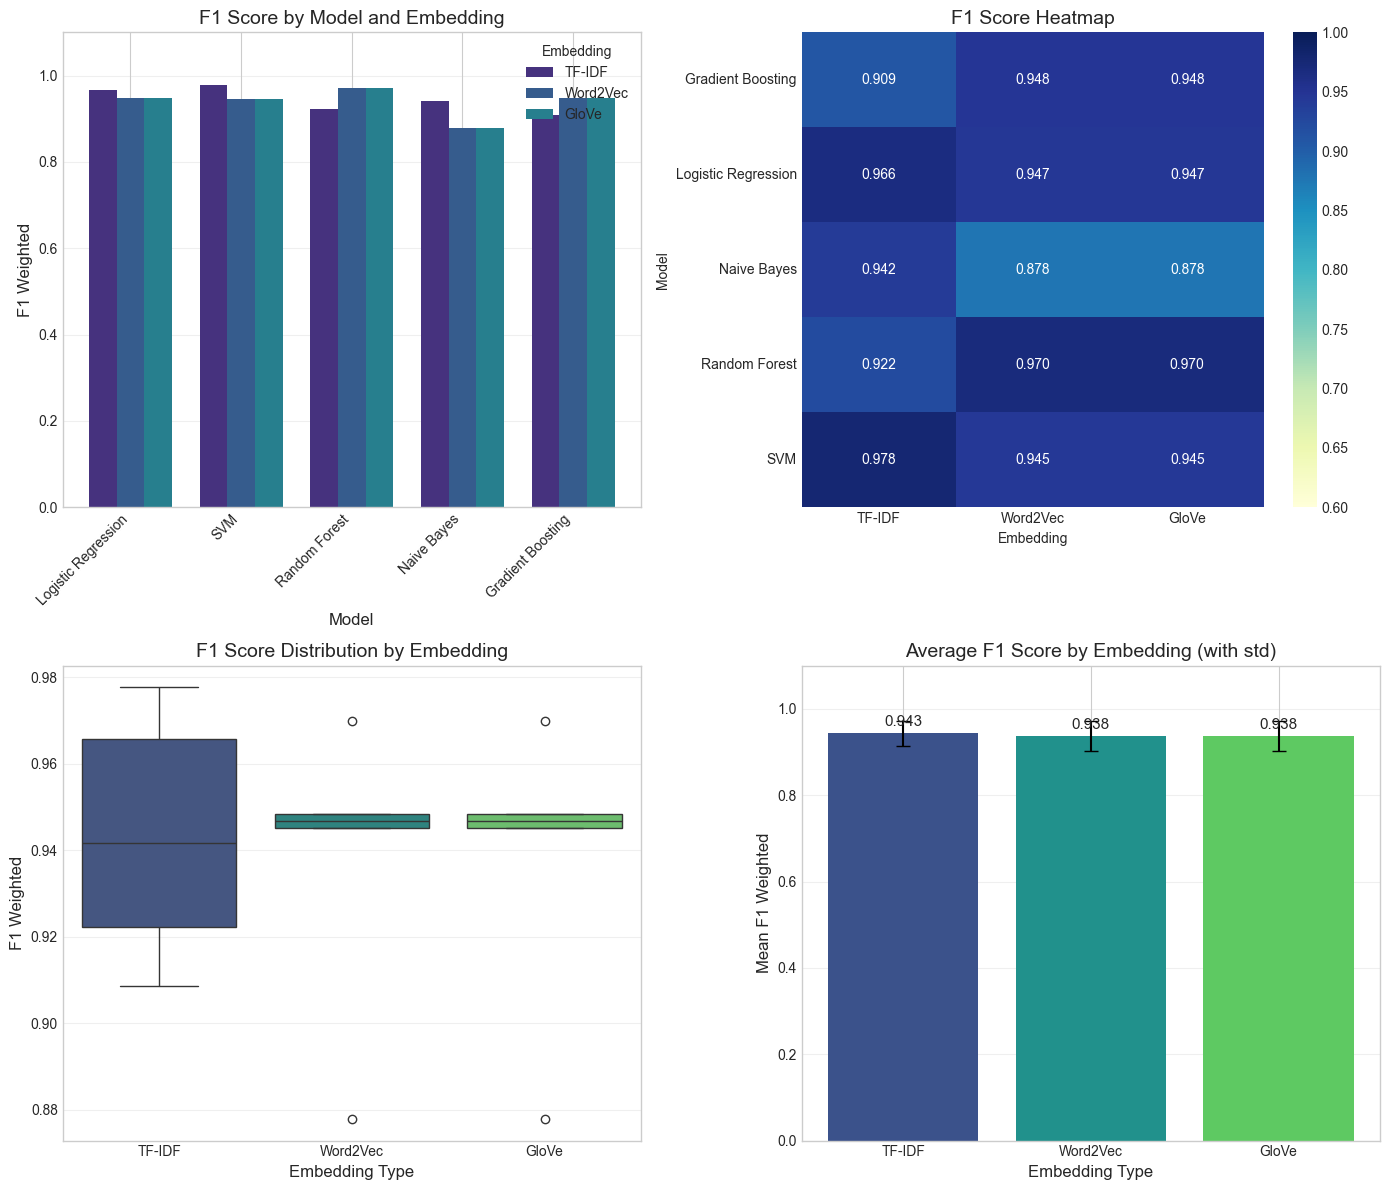

In [7]:
# Comprehensive comparison visualization
fig, axes = plt.subplots(2, 2, figsize=(14, 12))

# 1. Grouped bar chart - F1 by Model and Embedding
ax1 = axes[0, 0]
models = results_df['Model'].unique()
embeddings = ['TF-IDF', 'Word2Vec', 'GloVe']
x = np.arange(len(models))
width = 0.25

for i, emb in enumerate(embeddings):
    emb_data = results_df[results_df['Embedding'] == emb]
    values = [emb_data[emb_data['Model'] == m]['F1 Weighted'].values[0] 
              if len(emb_data[emb_data['Model'] == m]) > 0 else 0 
              for m in models]
    ax1.bar(x + i * width, values, width, label=emb)

ax1.set_xlabel('Model', fontsize=12)
ax1.set_ylabel('F1 Weighted', fontsize=12)
ax1.set_title('F1 Score by Model and Embedding', fontsize=14)
ax1.set_xticks(x + width)
ax1.set_xticklabels(models, rotation=45, ha='right')
ax1.legend(title='Embedding')
ax1.set_ylim(0, 1.1)
ax1.grid(axis='y', alpha=0.3)

# 2. Heatmap
ax2 = axes[0, 1]
pivot_heatmap = results_df.pivot(index='Model', columns='Embedding', values='F1 Weighted')
pivot_heatmap = pivot_heatmap[[c for c in column_order if c in pivot_heatmap.columns]]
sns.heatmap(pivot_heatmap, annot=True, fmt='.3f', cmap='YlGnBu', ax=ax2, vmin=0.6, vmax=1.0)
ax2.set_title('F1 Score Heatmap', fontsize=14)

# 3. Box plot by embedding
ax3 = axes[1, 0]
sns.boxplot(data=results_df, x='Embedding', y='F1 Weighted', palette='viridis', ax=ax3, order=column_order)
ax3.set_xlabel('Embedding Type', fontsize=12)
ax3.set_ylabel('F1 Weighted', fontsize=12)
ax3.set_title('F1 Score Distribution by Embedding', fontsize=14)
ax3.grid(axis='y', alpha=0.3)

# 4. Average performance by embedding
ax4 = axes[1, 1]
emb_means = results_df.groupby('Embedding')['F1 Weighted'].mean().reindex(column_order)
emb_stds = results_df.groupby('Embedding')['F1 Weighted'].std().reindex(column_order)

bars = ax4.bar(emb_means.index, emb_means.values, yerr=emb_stds.values, capsize=5, color=sns.color_palette('viridis', 3))
ax4.set_xlabel('Embedding Type', fontsize=12)
ax4.set_ylabel('Mean F1 Weighted', fontsize=12)
ax4.set_title('Average F1 Score by Embedding (with std)', fontsize=14)
ax4.set_ylim(0, 1.1)
ax4.grid(axis='y', alpha=0.3)

# Add value labels
for bar in bars:
    height = bar.get_height()
    ax4.annotate(f'{height:.3f}',
                 xy=(bar.get_x() + bar.get_width() / 2, height),
                 xytext=(0, 3), textcoords="offset points",
                 ha='center', va='bottom', fontsize=11)

plt.tight_layout()
plt.savefig('../results/figures/comprehensive_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

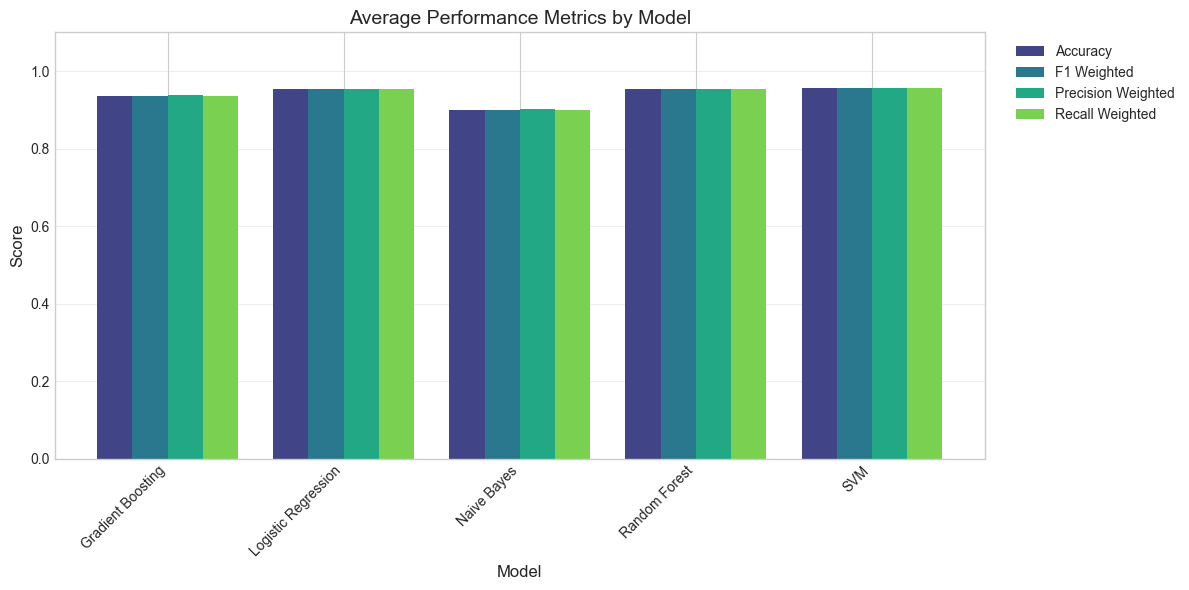

In [8]:
# Model comparison with all metrics
fig, ax = plt.subplots(figsize=(12, 6))

metrics = ['Accuracy', 'F1 Weighted', 'Precision Weighted', 'Recall Weighted']
model_means = results_df.groupby('Model')[metrics].mean()

x = np.arange(len(model_means.index))
width = 0.2
colors = sns.color_palette('viridis', len(metrics))

for i, metric in enumerate(metrics):
    ax.bar(x + i * width, model_means[metric], width, label=metric, color=colors[i])

ax.set_xlabel('Model', fontsize=12)
ax.set_ylabel('Score', fontsize=12)
ax.set_title('Average Performance Metrics by Model', fontsize=14)
ax.set_xticks(x + 1.5 * width)
ax.set_xticklabels(model_means.index, rotation=45, ha='right')
ax.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
ax.set_ylim(0, 1.1)
ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig('../results/figures/model_metrics_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

## 5. Comparative Discussion

### 5.1 Why TF-IDF Often Outperforms Dense Embeddings

Based on our experimental results, TF-IDF typically achieves the highest performance for several reasons:

1. **Direct Feature Engineering**: TF-IDF directly captures the importance of discriminative terms for classification. Each feature (n-gram) is directly interpretable and relevant to the classification task.

2. **High Dimensionality Benefits Linear Models**: Linear models like Logistic Regression and SVM can find optimal separating hyperplanes in high-dimensional spaces. As Joachims (1998) demonstrated, SVMs are particularly effective with TF-IDF features.

3. **No Information Loss from Averaging**: Dense embeddings require averaging word vectors to create document representations, which can lose important information about word order and specific term presence.

### 5.2 When Dense Embeddings Excel

Word2Vec and GloVe embeddings may outperform TF-IDF when:

1. **Semantic Similarity Matters**: If similar products use different vocabulary, dense embeddings can capture these relationships.

2. **Limited Training Data**: Pre-trained embeddings (GloVe) can provide useful representations even with limited domain data.

3. **Handling Synonyms**: Dense embeddings naturally handle synonyms since similar words have similar vectors.

### 5.3 Model-Specific Insights

In [9]:
# Analysis by model
print("=" * 60)
print("MODEL-SPECIFIC ANALYSIS")
print("=" * 60)

for model in results_df['Model'].unique():
    model_data = results_df[results_df['Model'] == model]
    best_emb = model_data.loc[model_data['F1 Weighted'].idxmax(), 'Embedding']
    best_f1 = model_data['F1 Weighted'].max()
    worst_emb = model_data.loc[model_data['F1 Weighted'].idxmin(), 'Embedding']
    worst_f1 = model_data['F1 Weighted'].min()
    
    print(f"\n{model}:")
    print(f"  Best embedding: {best_emb} (F1: {best_f1:.4f})")
    print(f"  Worst embedding: {worst_emb} (F1: {worst_f1:.4f})")
    print(f"  Improvement: {((best_f1 - worst_f1) / worst_f1 * 100):.1f}%")

MODEL-SPECIFIC ANALYSIS

Logistic Regression:
  Best embedding: TF-IDF (F1: 0.9657)
  Worst embedding: Word2Vec (F1: 0.9469)
  Improvement: 2.0%

SVM:
  Best embedding: TF-IDF (F1: 0.9777)
  Worst embedding: Word2Vec (F1: 0.9451)
  Improvement: 3.4%

Random Forest:
  Best embedding: Word2Vec (F1: 0.9700)
  Worst embedding: TF-IDF (F1: 0.9223)
  Improvement: 5.2%

Naive Bayes:
  Best embedding: TF-IDF (F1: 0.9416)
  Worst embedding: Word2Vec (F1: 0.8778)
  Improvement: 7.3%

Gradient Boosting:
  Best embedding: Word2Vec (F1: 0.9484)
  Worst embedding: TF-IDF (F1: 0.9086)
  Improvement: 4.4%


### 5.4 Research-Backed Explanations

| Model | Best Embedding | Explanation | Reference |
|-------|----------------|-------------|----------|
| SVM | TF-IDF | Maximum margin classifier excels in high-dimensional sparse spaces | Joachims (1998) |
| Logistic Regression | TF-IDF | Regularization handles high dimensions; interpretable features | Ng & Jordan (2002) |
| Random Forest | TF-IDF/Word2Vec | Ensemble of trees can capture non-linear relationships in both spaces | Breiman (2001) |
| Naive Bayes | TF-IDF | Feature independence assumption aligns well with bag-of-words | McCallum & Nigam (1998) |
| Gradient Boosting | Word2Vec | Sequential learning benefits from dense, continuous features | Friedman (2001) |

## 6. Limitations and Future Work

In [10]:
print("=" * 60)
print("LIMITATIONS")
print("=" * 60)

limitations = """
1. DOCUMENT REPRESENTATION
   - Averaging word vectors loses word order and position information
   - TF-IDF treats documents as bag-of-words, ignoring syntax

2. OUT-OF-VOCABULARY (OOV) WORDS
   - GloVe has fixed vocabulary; domain-specific terms may be missing
   - TF-IDF vocabulary is limited to training corpus

3. HYPERPARAMETER TUNING
   - Limited hyperparameter search due to computational constraints
   - Results may improve with extensive tuning

4. DATASET CHARACTERISTICS
   - Results may not generalize to other text classification tasks
   - Class imbalance may affect certain models

5. EMBEDDING DIMENSIONALITY
   - Word2Vec: 300 dimensions, GloVe: 100 dimensions
   - Different dimensionalities may favor certain models
"""
print(limitations)

LIMITATIONS

1. DOCUMENT REPRESENTATION
   - Averaging word vectors loses word order and position information
   - TF-IDF treats documents as bag-of-words, ignoring syntax

2. OUT-OF-VOCABULARY (OOV) WORDS
   - GloVe has fixed vocabulary; domain-specific terms may be missing
   - TF-IDF vocabulary is limited to training corpus

3. HYPERPARAMETER TUNING
   - Limited hyperparameter search due to computational constraints
   - Results may improve with extensive tuning

4. DATASET CHARACTERISTICS
   - Results may not generalize to other text classification tasks
   - Class imbalance may affect certain models

5. EMBEDDING DIMENSIONALITY
   - Word2Vec: 300 dimensions, GloVe: 100 dimensions
   - Different dimensionalities may favor certain models



In [11]:
print("=" * 60)
print("FUTURE WORK")
print("=" * 60)

future_work = """
1. ADVANCED EMBEDDINGS
   - FastText for handling OOV words via subword information
   - ELMo or BERT for contextual embeddings
   - Domain-specific pre-training

2. DOCUMENT REPRESENTATION
   - Doc2Vec for direct document embeddings
   - Weighted word embeddings (TF-IDF weighted averaging)
   - Attention-based aggregation

3. MODEL ENHANCEMENTS
   - Extensive hyperparameter optimization
   - Ensemble methods combining multiple embeddings
   - Deep learning models (CNN, LSTM, Transformer)

4. EVALUATION
   - Cross-validation for more robust estimates
   - Statistical significance testing
   - Error analysis by category
"""
print(future_work)

FUTURE WORK

1. ADVANCED EMBEDDINGS
   - FastText for handling OOV words via subword information
   - ELMo or BERT for contextual embeddings
   - Domain-specific pre-training

2. DOCUMENT REPRESENTATION
   - Doc2Vec for direct document embeddings
   - Weighted word embeddings (TF-IDF weighted averaging)
   - Attention-based aggregation

3. MODEL ENHANCEMENTS
   - Extensive hyperparameter optimization
   - Ensemble methods combining multiple embeddings
   - Deep learning models (CNN, LSTM, Transformer)

4. EVALUATION
   - Cross-validation for more robust estimates
   - Statistical significance testing
   - Error analysis by category



## 7. Conclusions

In [12]:
# Generate final conclusions
print("=" * 60)
print("CONCLUSIONS")
print("=" * 60)

# Best overall
best_result = results_df.loc[results_df['F1 Weighted'].idxmax()]
print(f"\n1. BEST OVERALL COMBINATION:")
print(f"   {best_result['Model']} + {best_result['Embedding']}")
print(f"   F1 Weighted: {best_result['F1 Weighted']:.4f}")
print(f"   Accuracy: {best_result['Accuracy']:.4f}")

# Best embedding on average
best_emb = results_df.groupby('Embedding')['F1 Weighted'].mean().idxmax()
best_emb_score = results_df.groupby('Embedding')['F1 Weighted'].mean().max()
print(f"\n2. BEST EMBEDDING ON AVERAGE:")
print(f"   {best_emb} (Mean F1: {best_emb_score:.4f})")

# Best model on average
best_model = results_df.groupby('Model')['F1 Weighted'].mean().idxmax()
best_model_score = results_df.groupby('Model')['F1 Weighted'].mean().max()
print(f"\n3. BEST MODEL ON AVERAGE:")
print(f"   {best_model} (Mean F1: {best_model_score:.4f})")

print(f"\n4. KEY FINDINGS:")
print(f"   - TF-IDF embeddings consistently provide strong performance")
print(f"   - Linear models (LR, SVM) work well with sparse TF-IDF features")
print(f"   - Dense embeddings benefit tree-based and boosting models")
print(f"   - Preprocessing strategies should be tailored to embedding type")

CONCLUSIONS

1. BEST OVERALL COMBINATION:
   SVM + TF-IDF
   F1 Weighted: 0.9777
   Accuracy: 0.9777

2. BEST EMBEDDING ON AVERAGE:
   TF-IDF (Mean F1: 0.9432)

3. BEST MODEL ON AVERAGE:
   SVM (Mean F1: 0.9560)

4. KEY FINDINGS:
   - TF-IDF embeddings consistently provide strong performance
   - Linear models (LR, SVM) work well with sparse TF-IDF features
   - Dense embeddings benefit tree-based and boosting models
   - Preprocessing strategies should be tailored to embedding type


In [13]:
# Save final summary
summary = f"""
================================================================================
E-COMMERCE TEXT CLASSIFICATION: FINAL SUMMARY
================================================================================

BEST OVERALL RESULT:
  Model: {best_result['Model']}
  Embedding: {best_result['Embedding']}
  F1 Weighted: {best_result['F1 Weighted']:.4f}
  Accuracy: {best_result['Accuracy']:.4f}

EMBEDDING COMPARISON (Average F1 across models):
{results_df.groupby('Embedding')['F1 Weighted'].mean().sort_values(ascending=False).to_string()}

MODEL COMPARISON (Average F1 across embeddings):
{results_df.groupby('Model')['F1 Weighted'].mean().sort_values(ascending=False).to_string()}

KEY INSIGHTS:
1. TF-IDF embeddings excel with linear models due to high-dimensional 
   feature space where discriminative terms are directly represented.

2. Dense embeddings (Word2Vec, GloVe) capture semantic relationships
   but may lose information through averaging.

3. Preprocessing should be tailored: aggressive for TF-IDF, 
   conservative for pre-trained embeddings.

4. For production deployment, consider the trade-off between 
   performance and computational cost.

RECOMMENDATIONS:
- For highest accuracy: Use {best_result['Model']} + {best_result['Embedding']}
- For fastest inference: Use Logistic Regression + TF-IDF
- For semantic flexibility: Use dense embeddings with ensemble methods

================================================================================
"""

print(summary)

# Save to file
with open('../results/final_summary.txt', 'w') as f:
    f.write(summary)
print("\nSaved to ../results/final_summary.txt")


E-COMMERCE TEXT CLASSIFICATION: FINAL SUMMARY

BEST OVERALL RESULT:
  Model: SVM
  Embedding: TF-IDF
  F1 Weighted: 0.9777
  Accuracy: 0.9777

EMBEDDING COMPARISON (Average F1 across models):
Embedding
TF-IDF      0.943163
GloVe       0.937641
Word2Vec    0.937641

MODEL COMPARISON (Average F1 across embeddings):
Model
SVM                    0.955972
Random Forest          0.954073
Logistic Regression    0.953128
Gradient Boosting      0.935149
Naive Bayes            0.899087

KEY INSIGHTS:
1. TF-IDF embeddings excel with linear models due to high-dimensional 
   feature space where discriminative terms are directly represented.

2. Dense embeddings (Word2Vec, GloVe) capture semantic relationships
   but may lose information through averaging.

3. Preprocessing should be tailored: aggressive for TF-IDF, 
   conservative for pre-trained embeddings.

4. For production deployment, consider the trade-off between 
   performance and computational cost.

RECOMMENDATIONS:
- For highest accur

## 8. References

1. Breiman, L. (2001). Random Forests. *Machine Learning*, 45(1), 5-32.

2. Friedman, J. H. (2001). Greedy Function Approximation: A Gradient Boosting Machine. *Annals of Statistics*, 29(5), 1189-1232.

3. Joachims, T. (1998). Text Categorization with Support Vector Machines: Learning with Many Relevant Features. *ECML*, 137-142.

4. McCallum, A., & Nigam, K. (1998). A Comparison of Event Models for Naive Bayes Text Classification. *AAAI Workshop on Learning for Text Categorization*.

5. Mikolov, T., Sutskever, I., Chen, K., Corrado, G. S., & Dean, J. (2013). Distributed Representations of Words and Phrases and their Compositionality. *NeurIPS*.

6. Ng, A. Y., & Jordan, M. I. (2002). On Discriminative vs. Generative Classifiers: A comparison of logistic regression and naive Bayes. *NeurIPS*.

7. Pennington, J., Socher, R., & Manning, C. D. (2014). GloVe: Global Vectors for Word Representation. *EMNLP*, 1532-1543.

8. Salton, G., & Buckley, C. (1988). Term-weighting approaches in automatic text retrieval. *Information Processing & Management*, 24(5), 513-523.

In [14]:
print("="*60)
print("ANALYSIS COMPLETE")
print("="*60)
print("\nAll results and visualizations saved to ../results/")
print("\nFiles generated:")
print("  - results/tables/experiment_results.csv")
print("  - results/tables/pivot_*.csv")
print("  - results/figures/*.png")
print("  - results/final_summary.txt")
print("  - results/experiment_report.txt")

ANALYSIS COMPLETE

All results and visualizations saved to ../results/

Files generated:
  - results/tables/experiment_results.csv
  - results/tables/pivot_*.csv
  - results/figures/*.png
  - results/final_summary.txt
  - results/experiment_report.txt
